# Analyse des ventes d'un distributeur d'électronique en SQL

**Auteurs :** Bakou KEITA, Florian NKOUAKE, Lukas EKLU, Maxime MIGNON

## Contexte

Projet « Stockage et organisation des données » : à partir de l'historique des ventes d'un distributeur d'électronique (magasins physiques et boutique en ligne, 8 pays, 2016-2021), il s'agit de :
1. **normaliser** les données brutes en 3e forme normale ;
2. **modéliser** la base (entités, relations, cardinalités) ;
3. **créer** la base de données ;
4. **calculer des KPI en SQL** et en tirer des recommandations.

Ce notebook reconstruit la base **SQLite** à partir des CSV (`build_database.py`), puis exécute les requêtes KPI du fichier [`sql/03_kpis.sql`](sql/03_kpis.sql). Chaque requête est affichée avant son résultat.

## 0. Préparation

In [1]:
import re
import sqlite3

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

import build_database

BLEU, ORANGE = '#2a78d6', '#eb6834'
FOND, ENCRE, ENCRE_2, ATTENUE, GRILLE, AXE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': FOND, 'axes.facecolor': FOND, 'savefig.facecolor': FOND,
    'axes.edgecolor': AXE, 'axes.labelcolor': ENCRE_2, 'text.color': ENCRE,
    'xtick.color': ATTENUE, 'ytick.color': ATTENUE,
    'axes.grid': True, 'grid.color': GRILLE, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'font.size': 10, 'figure.dpi': 110,
})
MILLIONS = FuncFormatter(lambda v, _: f'{v / 1e6:.0f} M$')
pd.set_option('display.float_format', lambda v: f'{v:,.1f}'.replace(',', ' '))


def sauvegarder(fig, nom):
    fig.tight_layout()
    fig.savefig(f'figures/{nom}.png', dpi=150, bbox_inches='tight')
    plt.show()


def charger_requetes(chemin):
    """Découpe un fichier SQL en requêtes nommées par des lignes « -- name: <nom> »."""
    blocs = re.split(r'^-- name: (\w+)\s*$', open(chemin, encoding='utf-8').read(), flags=re.M)[1:]
    return {nom: sql.strip() for nom, sql in zip(blocs[::2], blocs[1::2])}


REQUETES = charger_requetes('sql/03_kpis.sql')


def kpi(nom):
    """Affiche la requête SQL puis renvoie son résultat."""
    display(Markdown(f"```sql\n{REQUETES[nom]}\n```"))
    return pd.read_sql(REQUETES[nom], con)

In [2]:
import os
os.makedirs('figures', exist_ok=True)

# Construction de la base : schéma, chargement des CSV, vues, contrôles d'intégrité
con = build_database.construire()

Base créée : ventes.db
  countries            8 lignes
  customers        11887 lignes
  stores              58 lignes
  categories           8 lignes
  subcategories       32 lignes
  products          2492 lignes
  orders           26326 lignes
  order_lines      62884 lignes
  Clés étrangères et intégrité : OK


## 1. Modèle de données

Le modèle initial a été corrigé pour respecter réellement la **3e forme normale** :

| Problème du modèle initial | Correction |
|---|---|
| `Product_Categories` : sous-catégorie → catégorie → nom de catégorie (dépendance transitive) | Tables `subcategories` et `categories` séparées |
| `Transactions` : date, client et magasin dépendent du numéro de commande, pas de la ligne | Tables `orders` (en-tête) et `order_lines` (lignes) |
| Pays → continent répété pour chaque client | Table `countries` |
| Aucune clé primaire ni étrangère, colonnes `TEXT` nullables | Clés primaires et étrangères, `NOT NULL`, `CHECK`, index |
| Dates au format numéro de série Excel (`42370`), accents corrompus (`ThÃƒÂ¼ringen`) | Dates ISO 8601, encodage réparé au chargement |

Le schéma complet est dans [`sql/01_schema.sql`](sql/01_schema.sql), et la vue analytique `v_ventes` (une ligne par ligne de commande, avec chiffre d'affaires et marge) dans [`sql/02_vues.sql`](sql/02_vues.sql).

In [3]:
tables = ['countries', 'customers', 'stores', 'categories', 'subcategories', 'products', 'orders', 'order_lines']
display(pd.DataFrame({
    'table': tables,
    'lignes': [con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0] for t in tables],
    'clé primaire': [', '.join(r[1] for r in sorted(con.execute(f'PRAGMA table_info({t})'), key=lambda r: r[5]) if r[5])
                     for t in tables],
    'clés étrangères': [', '.join(f"{r[3]} → {r[2]}" for r in con.execute(f'PRAGMA foreign_key_list({t})')) or '-'
                        for t in tables],
}))

,table,lignes,clé primaire,clés étrangères
0,countries,8,country,-
1,customers,11887,customer_id,country → countries
2,stores,58,store_id,country → countries
3,categories,8,category_id,-
4,subcategories,32,subcategory_id,category_id → categories
5,products,2492,product_id,subcategory_id → subcategories
6,orders,26326,order_number,"store_id → stores, customer_id → customers"
7,order_lines,62884,"order_number, line_item","product_id → products, order_number → orders"


## 2. Vue d'ensemble

In [4]:
display(kpi('vue_ensemble'))

```sql
-- Chiffres clés sur toute la période
SELECT
    MIN(order_date)                                           AS debut,
    MAX(order_date)                                           AS fin,
    COUNT(DISTINCT order_number)                              AS commandes,
    COUNT(DISTINCT customer_id)                               AS clients,
    SUM(quantity)                                             AS unites,
    ROUND(SUM(chiffre_affaires))                              AS chiffre_affaires,
    ROUND(SUM(marge))                                         AS marge,
    ROUND(100.0 * SUM(marge) / SUM(chiffre_affaires), 1)      AS taux_marge_pct,
    ROUND(SUM(chiffre_affaires) / COUNT(DISTINCT order_number)) AS panier_moyen
FROM v_ventes;
```

,debut,fin,commandes,clients,unites,chiffre_affaires,marge,taux_marge_pct,panier_moyen
0,2016-01-01,2021-02-20,26326,11887,197757,55 755 480.0,32 662 688.0,58.6,2 118.0


**Analyse – Vue d'ensemble**
- En un peu plus de cinq ans (janvier 2016 à février 2021), **11 887 clients** ont passé **26 326 commandes** pour **55,8 M$** de chiffre d'affaires.
- Le taux de marge brute (prix catalogue moins coût du produit) est élevé et homogène : **58,6 %**.
- Le panier moyen est de **2 118 $** par commande.

## 3. Évolution des ventes

In [5]:
annuel = kpi('evolution_annuelle')
display(annuel)

```sql
-- Chiffre d'affaires par année et croissance sur un an (années complètes uniquement)
WITH annuel AS (
    SELECT
        annee,
        COUNT(DISTINCT strftime('%m', order_date)) AS mois_couverts,
        COUNT(DISTINCT order_number)               AS commandes,
        SUM(chiffre_affaires)                      AS ca,
        SUM(marge)                                 AS marge
    FROM v_ventes
    GROUP BY annee
)
SELECT
    annee,
    mois_couverts,
    commandes,
    ROUND(ca)    AS chiffre_affaires,
    ROUND(marge) AS marge,
    CASE WHEN mois_couverts = 12 AND LAG(mois_couverts) OVER (ORDER BY annee) = 12
         THEN ROUND(100.0 * (ca / LAG(ca) OVER (ORDER BY annee) - 1), 1)
    END          AS croissance_pct
FROM annuel
ORDER BY annee;
```

,annee,mois_couverts,commandes,chiffre_affaires,marge,croissance_pct
0,2016,12,2865,6 946 794.0,4 107 000.0,NaN
1,2017,12,3280,7 421 422.0,4 337 064.0,6.8
2,2018,12,5965,12 788 961.0,7 464 961.0,72.3
3,2019,12,9083,18 264 382.0,10 697 739.0,42.8
4,2020,12,4635,9 294 632.0,5 447 460.0,-49.1
5,2021,2,498,1 039 288.0,608 464.0,NaN


```sql
-- Chiffre d'affaires par trimestre, avec le rang du trimestre au sein de son année
SELECT
    annee,
    trimestre,
    SUM(quantity)                                                       AS unites,
    ROUND(SUM(chiffre_affaires))                                        AS chiffre_affaires,
    RANK() OVER (PARTITION BY annee ORDER BY SUM(chiffre_affaires) DESC) AS rang_dans_annee
FROM v_ventes
GROUP BY annee, trimestre
ORDER BY annee, trimestre;
```

,annee,trimestre,unites,chiffre_affaires,rang_dans_annee
0,2016,1,5687,1 879 424.0,2
1,2016,2,3836,1 225 163.0,4
2,2016,3,5068,1 569 894.0,3
3,2016,4,7170,2 272 312.0,1
4,2017,1,5805,1 751 890.0,3
5,2017,2,4065,1 306 570.0,4
6,2017,3,5897,1 791 541.0,2
7,2017,4,9031,2 571 421.0,1
8,2018,1,8705,2 696 369.0,3
9,2018,2,7450,2 117 868.0,4


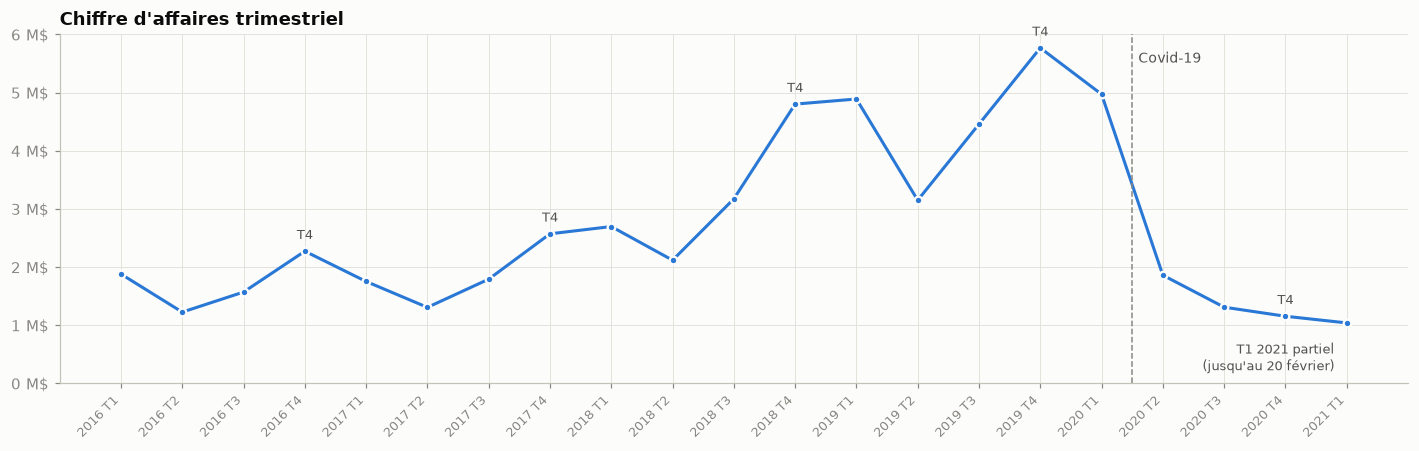

In [6]:
trimestres = kpi('ventes_trimestrielles')
display(trimestres)

trimestres['periode'] = trimestres['annee'].astype(str) + ' T' + trimestres['trimestre'].astype(str)
fig, ax = plt.subplots(figsize=(13, 4.2))
x = range(len(trimestres))
ax.plot(x, trimestres['chiffre_affaires'], color=BLEU, marker='o', markersize=5,
        markeredgecolor=FOND, markeredgewidth=1.5)
for i in trimestres.index[trimestres['trimestre'] == 4]:
    ax.annotate('T4', (i, trimestres.loc[i, 'chiffre_affaires']), textcoords='offset points',
                xytext=(0, 8), ha='center', color=ENCRE_2, fontsize=8.5)
i_covid = trimestres.index[trimestres['periode'] == '2020 T2'][0]
ax.axvline(i_covid - 0.5, color=ATTENUE, linestyle='--', linewidth=1)
ax.text(i_covid - 0.4, ax.get_ylim()[1] * 0.95, 'Covid-19', color=ENCRE_2, fontsize=9, va='top')
ax.annotate('T1 2021 partiel\n(jusqu\'au 20 février)', (len(trimestres) - 1, trimestres['chiffre_affaires'].iloc[-1]),
            textcoords='offset points', xytext=(-8, -12), ha='right', va='top', color=ENCRE_2, fontsize=8.5)
ax.set_xticks(list(x))
ax.set_xticklabels(trimestres['periode'], rotation=45, ha='right', fontsize=8.5)
ax.yaxis.set_major_formatter(MILLIONS)
ax.set_ylim(0, None)
ax.set_title("Chiffre d'affaires trimestriel")
sauvegarder(fig, '1_ca_trimestriel')

**Analyse – Évolution des ventes**
- **Forte croissance de 2016 à 2019** : le chiffre d'affaires passe de 6,9 M$ à 18,3 M$ (x 2,6), avec une accélération en 2018 (+72 %) et 2019 (+43 %).
- **Saisonnalité** : de 2016 à 2019, le 4e trimestre est chaque année le meilleur (fêtes de fin d'année) et le 2e trimestre le plus faible.
- **Rupture en 2020** : après un 1er trimestre record (5,0 M$), les ventes s'effondrent à partir d'avril 2020 et **ne se redressent pas** : 1,2 M$ au 4e trimestre 2020 contre 5,8 M$ un an plus tôt. Sur l'année, le chiffre d'affaires recule de 49 %. Le calendrier coïncide avec la pandémie de Covid-19.
- Le 1er trimestre 2021 ne couvre que sept semaines : il n'est pas comparable aux autres.

## 4. Canaux de vente : magasins et boutique en ligne

In [7]:
display(kpi('canaux'))

```sql
-- Magasins physiques ou boutique en ligne
SELECT
    canal,
    COUNT(DISTINCT order_number)                                               AS commandes,
    ROUND(SUM(chiffre_affaires))                                               AS chiffre_affaires,
    ROUND(100.0 * SUM(chiffre_affaires) / SUM(SUM(chiffre_affaires)) OVER (), 1) AS part_ca_pct,
    ROUND(SUM(chiffre_affaires) / COUNT(DISTINCT order_number))                AS panier_moyen,
    ROUND(100.0 * SUM(marge) / SUM(chiffre_affaires), 1)                       AS taux_marge_pct
FROM v_ventes
GROUP BY canal
ORDER BY chiffre_affaires DESC;
```

,canal,commandes,chiffre_affaires,part_ca_pct,panier_moyen,taux_marge_pct
0,Magasin,20746,44 351 155.0,79.5,2 138.0,58.6
1,En ligne,5580,11 404 325.0,20.5,2 044.0,58.5


```sql
-- Poids de la boutique en ligne dans le chiffre d'affaires de chaque année
SELECT
    annee,
    ROUND(SUM(CASE WHEN canal = 'En ligne' THEN chiffre_affaires ELSE 0 END)) AS ca_en_ligne,
    ROUND(SUM(chiffre_affaires))                                              AS ca_total,
    ROUND(100.0 * SUM(CASE WHEN canal = 'En ligne' THEN chiffre_affaires ELSE 0 END)
          / SUM(chiffre_affaires), 1)                                         AS part_en_ligne_pct
FROM v_ventes
GROUP BY annee
ORDER BY annee;
```

,annee,ca_en_ligne,ca_total,part_en_ligne_pct
0,2016,1 169 316.0,6 946 794.0,16.8
1,2017,1 388 497.0,7 421 422.0,18.7
2,2018,2 582 287.0,12 788 961.0,20.2
3,2019,3 908 496.0,18 264 382.0,21.4
4,2020,2 069 951.0,9 294 632.0,22.3
5,2021,285 778.0,1 039 288.0,27.5


```sql
-- Délai moyen entre commande et livraison (commandes en ligne livrées)
SELECT
    CAST(strftime('%Y', order_date) AS INTEGER)                    AS annee,
    COUNT(*)                                                       AS commandes_livrees,
    ROUND(AVG(julianday(delivery_date) - julianday(order_date)), 1) AS delai_moyen_jours
FROM orders
WHERE delivery_date IS NOT NULL
GROUP BY annee
ORDER BY annee;
```

,annee,commandes_livrees,delai_moyen_jours
0,2016,476,7.2
1,2017,644,5.2
2,2018,1245,4.4
3,2019,2006,4.1
4,2020,1071,4.0
5,2021,138,3.8


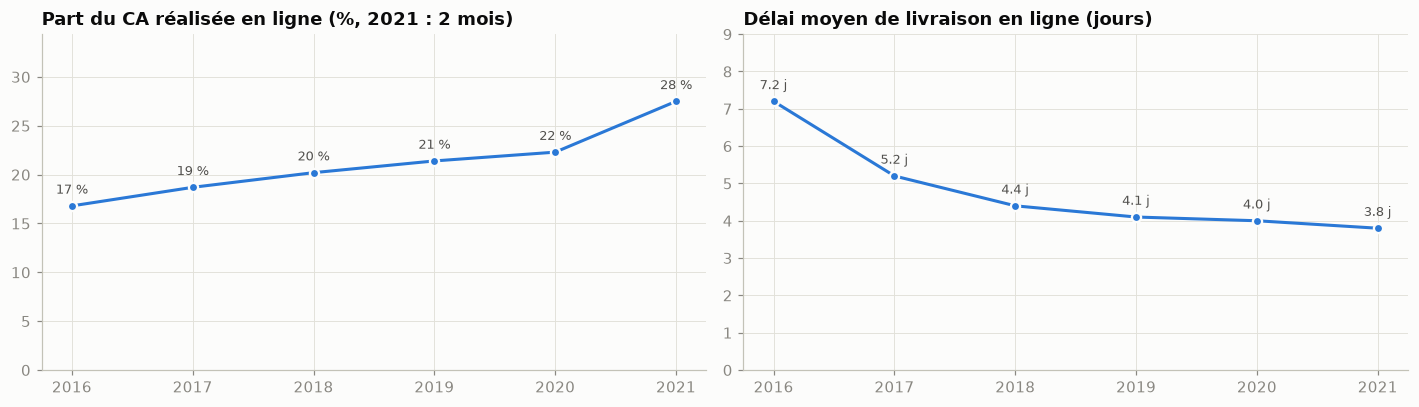

In [8]:
part_en_ligne = kpi('part_en_ligne_par_annee')
display(part_en_ligne)
delai = kpi('delai_livraison')
display(delai)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (df, col, titre, fmt) in zip(axes, [(part_en_ligne, 'part_en_ligne_pct', 'Part du CA réalisée en ligne (%, 2021 : 2 mois)', '{:.0f} %'),
                                            (delai, 'delai_moyen_jours', 'Délai moyen de livraison en ligne (jours)', '{:.1f} j')]):
    ax.plot(df['annee'], df[col], color=BLEU, marker='o', markersize=6, markeredgecolor=FOND, markeredgewidth=1.5)
    for x, v in zip(df['annee'], df[col]):
        ax.annotate(fmt.format(v), (x, v), textcoords='offset points', xytext=(0, 8), ha='center', color=ENCRE_2, fontsize=8.5)
    ax.set_ylim(0, df[col].max() * 1.25)
    ax.set_title(titre)
sauvegarder(fig, '2_canal_en_ligne')

**Analyse – Canaux de vente**
- **Les magasins physiques font 79,5 % du chiffre d'affaires.** La boutique en ligne pèse 20,5 % : contrairement à ce qu'indiquait le rapport initial, l'activité n'est pas principalement en ligne.
- Les deux canaux ont un panier moyen (2 138 $ contre 2 044 $) et un taux de marge (58,6 % contre 58,5 %) très proches.
- La part du web progresse régulièrement, de 16,8 % en 2016 à 22,3 % en 2020 (27,5 % sur les deux premiers mois de 2021). En 2020, la baisse touche les deux canaux, un peu moins la boutique en ligne (-47 % contre -50 % pour les magasins).
- Le **délai de livraison** des commandes en ligne a été divisé par près de deux : 7,2 jours en 2016, 3,8 jours en 2021.

## 5. Produits

```sql
-- Volume, chiffre d'affaires et rentabilité par catégorie de produits
SELECT
    categorie,
    SUM(quantity)                                                              AS unites,
    ROUND(SUM(chiffre_affaires))                                               AS chiffre_affaires,
    ROUND(100.0 * SUM(chiffre_affaires) / SUM(SUM(chiffre_affaires)) OVER (), 1) AS part_ca_pct,
    ROUND(SUM(chiffre_affaires) / SUM(quantity), 1)                            AS prix_moyen,
    ROUND(SUM(marge))                                                          AS marge,
    ROUND(100.0 * SUM(marge) / SUM(chiffre_affaires), 1)                       AS taux_marge_pct
FROM v_ventes
GROUP BY categorie
ORDER BY chiffre_affaires DESC;
```

,categorie,unites,chiffre_affaires,part_ca_pct,prix_moyen,marge,taux_marge_pct
0,Computers,44151,19 301 595.0,34.6,437.2,11 277 448.0,58.4
1,Home Appliances,18401,10 795 479.0,19.4,586.7,6 296 339.0,58.3
2,Cameras and camcorders,17609,6 520 168.0,11.7,370.3,3 919 801.0,60.1
3,Cell phones,31477,6 183 791.0,11.1,196.5,3 498 627.0,56.6
4,TV and Video,11236,5 928 983.0,10.6,527.7,3 536 694.0,59.7
5,Audio,23490,3 169 628.0,5.7,134.9,1 827 852.0,57.7
6,"Music, Movies and Audio Books",28802,3 131 006.0,5.6,108.7,1 909 259.0,61.0
7,Games and Toys,22591,724 829.0,1.3,32.1,396 669.0,54.7


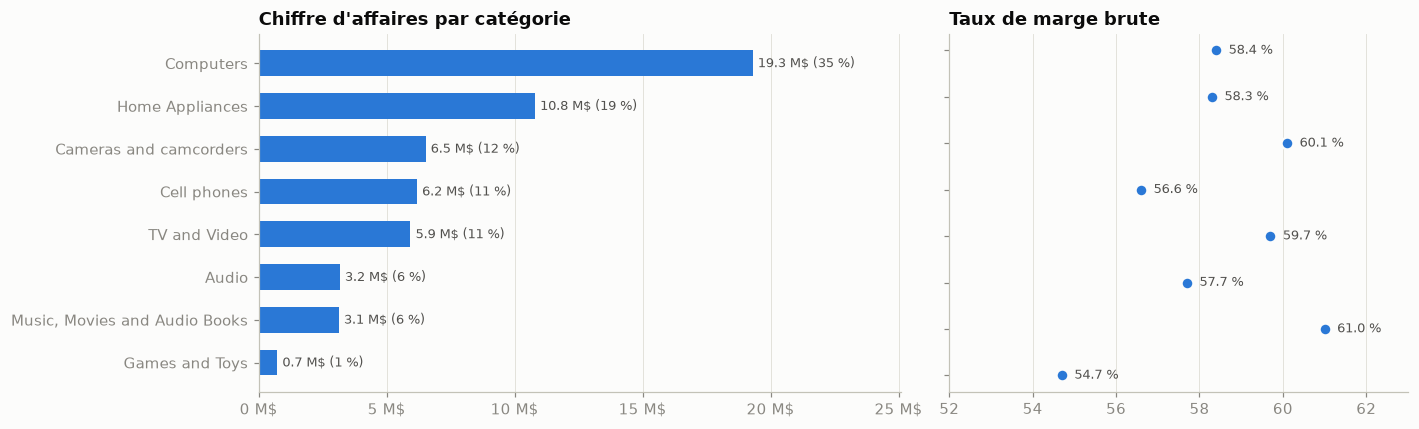

In [9]:
categories = kpi('categories')
display(categories)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1.4, 1]})
cats = categories.iloc[::-1]
axes[0].barh(cats['categorie'], cats['chiffre_affaires'], color=BLEU, height=0.6)
for y, (v, p) in enumerate(zip(cats['chiffre_affaires'], cats['part_ca_pct'])):
    axes[0].text(v + 2e5, y, f'{v / 1e6:.1f} M$ ({p:.0f} %)', va='center', color=ENCRE_2, fontsize=8.5)
axes[0].xaxis.set_major_formatter(MILLIONS)
axes[0].set_xlim(0, cats['chiffre_affaires'].max() * 1.3)
axes[0].grid(axis='y', visible=False)
axes[0].set_title("Chiffre d'affaires par catégorie")

axes[1].scatter(cats['taux_marge_pct'], cats['categorie'], color=BLEU, s=60, edgecolor=FOND, linewidth=1.5, zorder=3)
for y, v in enumerate(cats['taux_marge_pct']):
    axes[1].text(v + 0.3, y, f'{v:.1f} %', va='center', color=ENCRE_2, fontsize=8.5)
axes[1].set_xlim(52, 63)
axes[1].set_yticklabels([])
axes[1].grid(axis='y', visible=False)
axes[1].set_title('Taux de marge brute')
sauvegarder(fig, '3_categories')

In [10]:
display(kpi('top_produits'))

```sql
-- Top 10 des produits par chiffre d'affaires
SELECT
    RANK() OVER (ORDER BY SUM(chiffre_affaires) DESC) AS rang,
    produit,
    categorie,
    SUM(quantity)                                     AS unites,
    ROUND(SUM(chiffre_affaires))                      AS chiffre_affaires,
    ROUND(SUM(marge))                                 AS marge
FROM v_ventes
GROUP BY product_id, produit, categorie
ORDER BY chiffre_affaires DESC
LIMIT 10;
```

,rang,produit,categorie,unites,chiffre_affaires,marge
0,1,WWI Desktop PC2.33 X2330 Black,Computers,550,505 450.0,337 986.0
1,2,Adventure Works Desktop PC2.33 XD233 Silver,Computers,481,466 089.0,311 664.0
2,3,Adventure Works Desktop PC2.33 XD233 Brown,Computers,479,464 151.0,310 368.0
3,4,Adventure Works Desktop PC2.33 XD233 Black,Computers,462,447 678.0,299 353.0
4,5,Adventure Works Desktop PC2.33 XD233 White,Computers,451,437 019.0,292 225.0
5,6,WWI Desktop PC2.33 X2330 White,Computers,462,424 578.0,283 908.0
6,7,WWI Desktop PC2.33 X2330 Brown,Computers,460,422 740.0,282 679.0
7,8,"Adventure Works 52"" LCD HDTV X590 White",TV and Video,136,394 399.0,263 727.0
8,9,"Adventure Works 52"" LCD HDTV X590 Black",TV and Video,129,374 099.0,250 153.0
9,10,WWI Desktop PC2.33 X2330 Silver,Computers,392,360 248.0,240 892.0


**Analyse – Produits**
- **Les ordinateurs dominent** : 34,6 % du chiffre d'affaires (19,3 M$), suivis de l'électroménager (19,4 %), qui génère beaucoup de valeur avec peu d'unités grâce à un prix moyen élevé (587 $).
- **Le taux de marge varie peu d'une catégorie à l'autre** (de 54,7 % à 61,0 %). La catégorie « Music, Movies and Audio Books » a même **le meilleur taux de marge (61,0 %)** : son chiffre d'affaires est faible parce que ses prix sont bas (109 $ en moyenne), pas parce que ses marges seraient réduites, comme l'affirmait le rapport initial.
- « Games and Toys » est la seule catégorie marginale : 1,3 % du chiffre d'affaires, avec des produits à 32 $ en moyenne.
- Le top 10 des produits est composé à 80 % d'**ordinateurs de bureau** (gammes WWI et Adventure Works Desktop PC2.33, déclinées en plusieurs coloris), complété par deux téléviseurs LCD 52 pouces.

## 6. Géographie

In [11]:
display(kpi('continents'))

```sql
-- Ventes par continent du client
SELECT
    continent_client                                                           AS continent,
    SUM(quantity)                                                              AS unites,
    ROUND(SUM(chiffre_affaires))                                               AS chiffre_affaires,
    ROUND(100.0 * SUM(chiffre_affaires) / SUM(SUM(chiffre_affaires)) OVER (), 1) AS part_ca_pct
FROM v_ventes
GROUP BY continent_client
ORDER BY chiffre_affaires DESC;
```

,continent,unites,chiffre_affaires,part_ca_pct
0,North America,123200,34 595 966.0,62.0
1,Europe,65348,18 451 376.0,33.1
2,Australia,9209,2 708 138.0,4.9


```sql
-- Ventes et panier moyen par pays du client
SELECT
    pays_client                                                                AS pays,
    COUNT(DISTINCT order_number)                                               AS commandes,
    SUM(quantity)                                                              AS unites,
    ROUND(SUM(chiffre_affaires))                                               AS chiffre_affaires,
    ROUND(100.0 * SUM(chiffre_affaires) / SUM(SUM(chiffre_affaires)) OVER (), 1) AS part_ca_pct,
    ROUND(SUM(chiffre_affaires) / COUNT(DISTINCT order_number))                AS panier_moyen
FROM v_ventes
GROUP BY pays_client
ORDER BY chiffre_affaires DESC;
```

,pays,commandes,unites,chiffre_affaires,part_ca_pct,panier_moyen
0,United States,14221,106407,29 871 631.0,53.6,2 101.0
1,United Kingdom,3421,25298,7 084 088.0,12.7,2 071.0
2,Germany,2440,18943,5 414 150.0,9.7,2 219.0
3,Canada,2281,16793,4 724 335.0,8.5,2 071.0
4,Australia,1182,9209,2 708 138.0,4.9,2 291.0
5,Italy,1101,8470,2 475 646.0,4.4,2 249.0
6,Netherlands,976,7252,1 962 154.0,3.5,2 010.0
7,France,704,5385,1 515 338.0,2.7,2 152.0


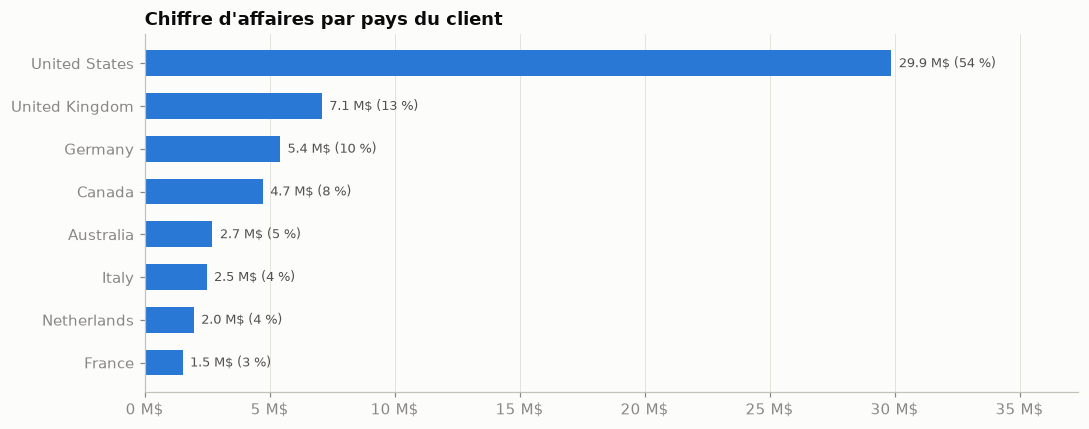

In [12]:
pays = kpi('pays')
display(pays)

fig, ax = plt.subplots(figsize=(10, 4))
p = pays.iloc[::-1]
ax.barh(p['pays'], p['chiffre_affaires'], color=BLEU, height=0.6)
for y, (v, part) in enumerate(zip(p['chiffre_affaires'], p['part_ca_pct'])):
    ax.text(v + 3e5, y, f'{v / 1e6:.1f} M$ ({part:.0f} %)', va='center', color=ENCRE_2, fontsize=8.5)
ax.xaxis.set_major_formatter(MILLIONS)
ax.set_xlim(0, p['chiffre_affaires'].max() * 1.25)
ax.grid(axis='y', visible=False)
ax.set_title("Chiffre d'affaires par pays du client")
sauvegarder(fig, '4_pays')

In [13]:
display(kpi('top_villes'))

```sql
-- Top 10 des villes par chiffre d'affaires
-- Regroupement par ville ET pays : il existe un Toronto au Canada et un autre aux États-Unis
SELECT
    RANK() OVER (ORDER BY SUM(chiffre_affaires) DESC) AS rang,
    ville_client                                      AS ville,
    etat_client                                       AS etat,
    pays_client                                       AS pays,
    COUNT(DISTINCT customer_id)                       AS clients,
    SUM(quantity)                                     AS unites,
    ROUND(SUM(chiffre_affaires))                      AS chiffre_affaires
FROM v_ventes
GROUP BY ville_client, etat_client, pays_client
ORDER BY chiffre_affaires DESC
LIMIT 10;
```

,rang,ville,etat,pays,clients,unites,chiffre_affaires
0,1,Toronto,Ontario,Canada,156,2174,600 638.0
1,2,New York,New York,United States,111,1806,492 392.0
2,3,Los Angeles,California,United States,94,1812,467 985.0
3,4,Houston,Texas,United States,77,1307,360 714.0
4,5,Philadelphia,Pennsylvania,United States,48,1133,358 601.0
5,6,Chicago,Illinois,United States,72,1146,349 357.0
6,7,Dallas,Texas,United States,56,843,283 011.0
7,8,Montreal,Quebec,Canada,70,1089,266 845.0
8,9,Atlanta,Georgia,United States,45,790,241 893.0
9,10,Calgary,Alberta,Canada,53,805,217 303.0


**Analyse – Géographie**
- **Les États-Unis réalisent 53,6 % du chiffre d'affaires** (29,9 M$), loin devant le Royaume-Uni (12,7 %) et l'Allemagne (9,7 %). L'Amérique du Nord pèse 62 %, l'Europe 33 % et l'Australie 5 %.
- Le **panier moyen** varie peu entre pays : de 2 010 $ (Pays-Bas) à 2 291 $ (Australie). L'Australie a bien le panier le plus élevé, mais l'écart avec la moyenne est d'environ 8 %.
- **Toronto** est la première ville (600 638 $), devant New York et Los Angeles.
- Correction par rapport au livrable initial : le top 10 des villes regroupait les villes par nom uniquement. Or il existe un Toronto au Canada et un autre aux États-Unis (de même pour Houston) : leurs ventes étaient additionnées. En regroupant par ville, État et pays, Portland sort du classement et Calgary y entre.

## 7. Clients

In [14]:
display(kpi('top_clients'))

```sql
-- Top 10 des clients par chiffre d'affaires
SELECT
    RANK() OVER (ORDER BY SUM(chiffre_affaires) DESC)          AS rang,
    customer_id,
    pays_client                                                AS pays,
    COUNT(DISTINCT order_number)                               AS commandes,
    SUM(quantity)                                              AS unites,
    ROUND(SUM(chiffre_affaires))                               AS chiffre_affaires,
    ROUND(SUM(chiffre_affaires) / COUNT(DISTINCT order_number)) AS panier_moyen
FROM v_ventes
GROUP BY customer_id, pays_client
ORDER BY chiffre_affaires DESC
LIMIT 10;
```

,rang,customer_id,pays,commandes,unites,chiffre_affaires,panier_moyen
0,1,1702221,United States,9,75,61 872.0,6 875.0
1,2,1884663,United States,3,30,43 518.0,14 506.0
2,3,1969704,United States,7,60,42 788.0,6 113.0
3,4,535496,Germany,3,35,41 522.0,13 841.0
4,5,551036,Germany,4,36,40 557.0,10 139.0
5,6,723572,Italy,14,124,40 225.0,2 873.0
6,7,262871,Canada,3,32,38 814.0,12 938.0
7,8,1928466,United States,4,40,38 191.0,9 548.0
8,9,1503831,United States,3,29,37 320.0,12 440.0
9,10,1373561,United States,5,62,36 817.0,7 363.0


```sql
-- Répartition des clients selon leur nombre de commandes
WITH par_client AS (
    SELECT customer_id, COUNT(*) AS nb_commandes
    FROM orders
    GROUP BY customer_id
)
SELECT
    CASE WHEN nb_commandes >= 5 THEN '5 et plus' ELSE CAST(nb_commandes AS TEXT) END AS commandes_par_client,
    COUNT(*)                                                                        AS clients,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                              AS part_clients_pct
FROM par_client
GROUP BY commandes_par_client
ORDER BY MIN(nb_commandes);
```

,commandes_par_client,clients,part_clients_pct
0,1,4615,38.8
1,2,3410,28.7
2,3,2003,16.9
3,4,1053,8.9
4,5 et plus,806,6.8


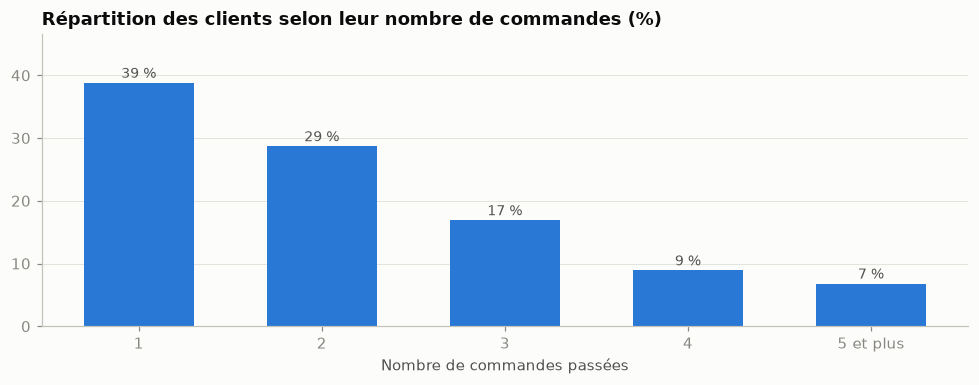

In [15]:
frequence = kpi('frequence_achat')
display(frequence)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(frequence['commandes_par_client'], frequence['part_clients_pct'], color=BLEU, width=0.6)
for x, v in enumerate(frequence['part_clients_pct']):
    ax.text(x, v + 0.8, f'{v:.0f} %', ha='center', color=ENCRE_2, fontsize=9)
ax.set_ylim(0, frequence['part_clients_pct'].max() * 1.2)
ax.grid(axis='x', visible=False)
ax.set_xlabel('Nombre de commandes passées')
ax.set_title('Répartition des clients selon leur nombre de commandes (%)')
sauvegarder(fig, '5_frequence_achat')

**Analyse – Clients**
- Les meilleurs clients doivent leur rang à **quelques commandes de montant élevé** plutôt qu'à un grand nombre d'achats : 9 des 10 premiers ont passé entre 3 et 9 commandes, avec des paniers moyens de 6 000 à 14 500 $. Le client 723572 fait exception, avec 14 commandes et 124 unités.
- **39 % des clients n'ont commandé qu'une seule fois**, et seuls 16 % ont passé 4 commandes ou plus. La fidélisation est un levier de croissance important : chaque client récurrent supplémentaire pèse en moyenne plus de 2 000 $ par commande.

## 8. Conclusions et recommandations

**Constats**
1. L'entreprise est avant tout un **réseau de magasins physiques** (79,5 % du CA), concentré sur l'Amérique du Nord (62 %) et en particulier les États-Unis (54 %).
2. Après une forte croissance de 2016 à 2019 (x 2,6), les ventes ont été **divisées par deux en 2020** et ne s'étaient pas redressées début 2021.
3. Les **ordinateurs** et l'**électroménager** font plus de la moitié du chiffre d'affaires. Les taux de marge sont homogènes (55-61 %) : la rentabilité dépend surtout du volume et du prix, pas de la catégorie.
4. La **boutique en ligne** gagne du terrain (de 17 % à 22 % du CA) et livre deux fois plus vite qu'en 2016.
5. **39 % des clients n'achètent qu'une fois.**

**Recommandations**
1. **Relance post-Covid** : prioriser la reconquête du trafic en magasin, principal canal, et analyser le recul magasin par magasin pour cibler les points de vente les plus touchés.
2. **Accélérer le canal en ligne** : sa part progresse chaque année, il a un peu mieux résisté en 2020, et son panier comme sa marge sont équivalents à ceux des magasins.
3. **Fidélisation** : programme de réachat ciblant les clients à commande unique (39 % de la base), en s'appuyant sur les catégories à fort panier (ordinateurs, électroménager).
4. **Saisonnalité** : concentrer les stocks et les campagnes sur le 4e trimestre, et utiliser le 2e trimestre, structurellement creux, pour des opérations promotionnelles.

## 9. Écarts avec le livrable initial

| Livrable initial | Constat après vérification |
|---|---|
| Analyse des ventes « du site internet » | 79,5 % du CA est réalisé en magasin, 20,5 % en ligne |
| « Music, Movies and Audio Books » : marges réduites | Meilleur taux de marge de toutes les catégories (61,0 %) ; le CA est faible car les prix sont bas |
| « Croissance soutenue » des ventes | Vrai jusqu'en 2019, puis -49 % en 2020 ; l'analyse s'arrêtait au 2e trimestre 2020 |
| « 7 170 transactions » au 4e trimestre 2016 | 7 170 **unités vendues** (la requête additionne des quantités) |
| Top 10 des villes groupé par nom de ville | Des villes homonymes de pays différents étaient additionnées (Toronto, Houston) |
| Base conforme à la 3FN, avec clés primaires et étrangères | Dépendances transitives (catégories, commandes) et aucune clé dans le dump : corrigé dans `sql/01_schema.sql` |

In [16]:
con.close()